# étoiles Be avec compagne sd0 : [Le projet](https://gilgamir.github.io/be-binaries)

## chargement de la cible et correction barycentrique

In [110]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.modeling import models, fitting
from astropy.coordinates import SkyCoord, EarthLocation
from specutils import Spectrum, SpectralRegion
from astropy import units as u
from astropy.time import Time
from specutils.analysis import centroid, fwhm, equivalent_width, snr, snr_derived

# ATTENTION : le spectre autour de H alpha d'une étoile Be est un 'shell', i.e. une enveloppe de gaz autour de l'étoile
# -> le modèle à ajuster n'est PAS une double gaussienne mais une large gaussienne en émission, 'percée' d'une étroite gaussienne en absorption

# on charge le spectre
#filename = 'data/plouis/_60cyg_20261113_939_tell.fits'
#filename = 'data/plouis/_28cyg_20261113_852_tell.fits'
filename = 'data/plouis/_59cyg_20261113_899_tell.fits'

use_central_abs = False  # True si un creux central net existe (ex. Be classiques commes 28 Cyg) ; False pour 59 Cyg (dégénéré)


sp = Spectrum.read(filename)
#print(sp.meta)

# coordonnées du CALC - normalement dans l'entete FITS
LAT=48.12*u.deg
LON=-1.63*u.deg
HEIGHT=10*u.m

# Correction de la vitesse barycentrique de la Terre (Rennes)
c = 299792458  # m/s 
location = EarthLocation(lat=LAT, lon=LON, height=HEIGHT)   
target = SkyCoord.from_name(sp.meta['header']['OBJECT'])
t = Time(float(sp.meta['header']['JD-OBS']), format='jd', scale='utc')
v_bary = target.radial_velocity_correction(kind='barycentric', obstime=t, location=location)
beta = v_bary / c * u.Unit('m/s')
doppler_factor = np.sqrt((1 + beta.value) / (1 - beta.value))  
lambda_corrected = sp.spectral_axis * doppler_factor
spec_corrected = Spectrum(spectral_axis=lambda_corrected, flux=sp.flux)

print(f"{v_bary=}, {doppler_factor=}")    
print(f"Décalage moyen : {np.mean((lambda_corrected - sp.spectral_axis).value):.6f} Å")

# Extraction des valeurs brutes (pour éviter les soucis avec les unités astropy)
x_data = spec_corrected.spectral_axis.value
y_data = spec_corrected.flux.value 


v_bary=<Quantity -14174.19013973 m / s>, doppler_factor=np.float64(0.9999527211085555)
Décalage moyen : -0.312058 Å


## double ajustement des deux ailes de H alpha

------------------------------------------------------------
Résolution (Néon)           : 0.412 A    | rms ajustement : 0.0201
Largeur commune V/R (sigma) : 2.05 A | piédestal FWHM : 11.0 A
Pics du profil   : NON résolus dans le profil ajusté (épaulement) -> utiliser les composantes
Composantes      V = 6560.391 +/- 0.072   R = 6565.076 +/- 0.037 A
   séparation : 4.686 A -> vitesse 107.0 km/s (dépend du modèle)
   V/R (amplitudes gaussiennes) : 1.433
------------------------------------------------------------


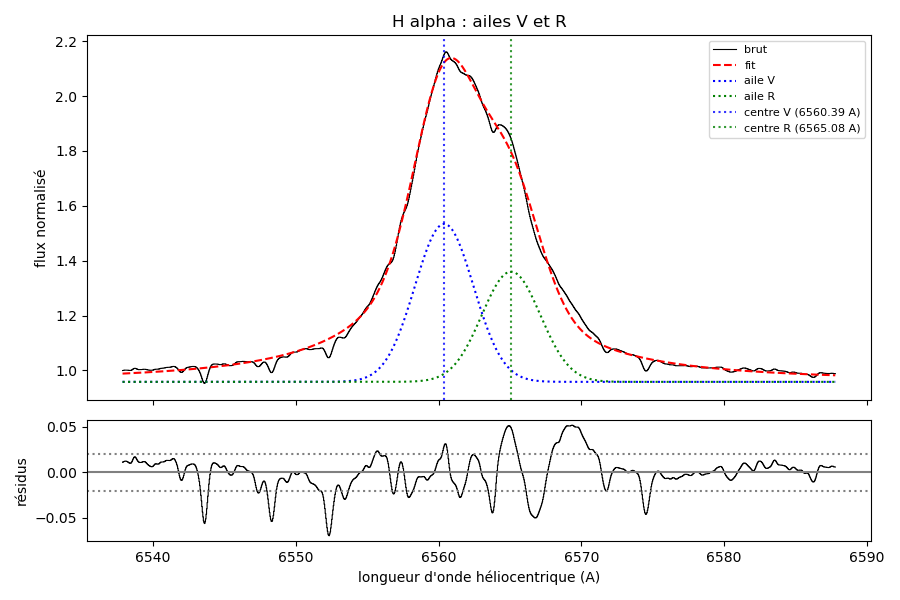

In [113]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.modeling import models, fitting
from scipy.signal import find_peaks
import astropy.units as u

c = 299792.458      # km/s
fwhm_neon_pix = 5.45   # largeur raie néon en px, retourné par specinti
disp_physique = 0.0756 # A/pixel dispersion du starEx2400, retourné par specinti

lambda_ha = 6562.82
window_width = 25      # nb angstroms de chaque côté
v_lim = 450.           # km/s : domaine autorisé pour les centres V et R (de part et d'autre de lambda_ha)

## Découpage de la zone
mask = (x_data > lambda_ha - window_width) & (x_data < lambda_ha + window_width)
x_win = x_data[mask]
y_win = y_data[mask]

# ---------------------------------------------------------------------------
# Modèle : continuum + aile bleue (V) + aile rouge (R) + piédestal large [+ creux central]
#  - V et R : 2 gaussiennes de MÊME largeur, centres bornés de chaque côté de lambda_ha
#  - piédestal lorentzien : ailes larges communes (diffusion électronique) -> évite que V et R
#    ne servent à décrire les ailes, ce qui faisait diverger l'ajustement à 2 gaussiennes
# ---------------------------------------------------------------------------
dl = lambda_ha * v_lim / c
cont = models.Const1D(amplitude=1.0, bounds={'amplitude': (0.9, 1.1)}, name='cont')
g_V  = models.Gaussian1D(amplitude=0.5, mean=lambda_ha - 1.5, stddev=1.5,
                         bounds={'amplitude': (0, 3), 'mean': (lambda_ha - dl, lambda_ha), 'stddev': (0.5, 5)}, name='V')
g_R  = models.Gaussian1D(amplitude=0.5, mean=lambda_ha + 1.5, stddev=1.5,
                         bounds={'amplitude': (0, 3), 'mean': (lambda_ha, lambda_ha + dl), 'stddev': (0.5, 5)}, name='R')
g_R.stddev.tied = lambda m: m['V'].stddev                   # même largeur pour V et R
ped  = models.Lorentz1D(amplitude=0.5, x_0=lambda_ha, fwhm=6,
                         bounds={'amplitude': (0, 3), 'x_0': (lambda_ha - 1.5, lambda_ha + 1.5), 'fwhm': (2, 30)}, name='ped')
model_init = cont + g_V + g_R + ped
if use_central_abs:
    absn = models.Gaussian1D(amplitude=-0.1, mean=lambda_ha, stddev=0.8,
                             bounds={'amplitude': (-1, 0), 'mean': (lambda_ha - 1.5, lambda_ha + 1.5), 'stddev': (0.2, 2)}, name='abs')
    model_init = model_init + absn

fitter = fitting.LevMarLSQFitter(calc_uncertainties=True)
fit_result = fitter(model_init, x_win, y_win, maxiter=2000)

# courbe fittée sur une grille fine (0.01 A) pour trouver les maxima avec précision
x_fine = np.arange(x_win.min(), x_win.max(), 0.01)
y_fit = fit_result(x_fine)
y_fit_win = fit_result(x_win)
rms = np.std(y_win - y_fit_win)

# ---------------------------------------------------------------------------
# 1) pics du PROFIL ajusté : maxima locaux de part et d'autre de la vallée centrale
# ---------------------------------------------------------------------------
sel = (x_fine > lambda_ha - dl) & (x_fine < lambda_ha + dl)
pk, _ = find_peaks(y_fit[sel])
resolved = len(pk) >= 2
if resolved:
    pk = pk[np.argsort(y_fit[sel][pk])[-2:]]              # les 2 maxima les plus hauts
    pk = np.sort(pk)
    x_V, x_R = x_fine[sel][pk[0]], x_fine[sel][pk[1]]
    V_amplitude, R_amplitude = y_fit[sel][pk[0]], y_fit[sel][pk[1]]
else:
    x_V = x_R = V_amplitude = R_amplitude = np.nan

# ---------------------------------------------------------------------------
# 2) centres des composantes V et R (dépendent du modèle, mais existent même si les pics sont fondus)
# ---------------------------------------------------------------------------
cV, cR = fit_result['V'].mean.value, fit_result['R'].mean.value
try:
    ecV, ecR = fit_result['V'].mean.std, fit_result['R'].mean.std
except Exception:
    ecV = ecR = np.nan

# incertitude instrumentale (néon) sur la position d'un pic : 1/10 de la FWHM
fwhm_inst_a = fwhm_neon_pix * disp_physique
err_pos = fwhm_inst_a / 10.0
err_delta_lambda = np.sqrt(2) * err_pos

def v_disk(dL):  return c * dL / lambda_ha / 2

print("-" * 60)
print(f"Résolution (Néon)           : {fwhm_inst_a:.3f} A    | rms ajustement : {rms:.4f}")
print(f"Largeur commune V/R (sigma) : {fit_result['V'].stddev.value:.2f} A | piédestal FWHM : {fit_result['ped'].fwhm.value:.1f} A")
if resolved:
    dL = x_R - x_V
    print(f"Pics du profil   V = {x_V:.3f}   R = {x_R:.3f} A   (+/- {err_pos:.3f})")
    print(f"   séparation : {dL:.3f} +/- {err_delta_lambda:.3f} A -> vitesse bord du disque {v_disk(dL):.1f} +/- {c*err_delta_lambda/(2*lambda_ha):.1f} km/s")
    print(f"   V/R (flux aux pics) : {V_amplitude / R_amplitude:.3f}")
else:
    print("Pics du profil   : NON résolus dans le profil ajusté (épaulement) -> utiliser les composantes")
dLc = cR - cV
print(f"Composantes      V = {cV:.3f} +/- {ecV:.3f}   R = {cR:.3f} +/- {ecR:.3f} A")
print(f"   séparation : {dLc:.3f} A -> vitesse {v_disk(dLc):.1f} km/s (dépend du modèle)")
print(f"   V/R (amplitudes gaussiennes) : {fit_result['V'].amplitude.value / fit_result['R'].amplitude.value:.3f}")
print("-" * 60)

# ---------------------------------------------------------------------------
# affichage matplotlib classique (spectre + composantes, puis résidus)
# ---------------------------------------------------------------------------
c0 = fit_result['cont'].amplitude.value
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ax[0].plot(x_win, y_win, 'k', lw=0.8, drawstyle='steps-mid', label='brut')
ax[0].plot(x_fine, y_fit, 'r--', label='fit')
ax[0].plot(x_fine, c0 + fit_result['V'](x_fine), 'b:', label='aile V')
ax[0].plot(x_fine, c0 + fit_result['R'](x_fine), 'g:', label='aile R')
#ax[0].plot(x_fine, c0 + fit_result['ped'](x_fine), color='gray', ls=':', label='piédestal')
#if use_central_abs:
 #   ax[0].plot(x_fine, c0 + fit_result['abs'](x_fine), color='purple', ls=':', label='creux central')
if resolved:
    ax[0].axvline(x_V, color='blue', alpha=0.8, label=f'pic V ({x_V:.2f} A)')
    ax[0].axvline(x_R, color='green', alpha=0.8, label=f'pic R ({x_R:.2f} A)')
ax[0].axvline(cV, color='blue', ls=':', alpha=0.8, label=f'centre V ({cV:.2f} A)')
ax[0].axvline(cR, color='green', ls=':', alpha=0.8, label=f'centre R ({cR:.2f} A)')
ax[0].set_ylabel('flux normalisé')
ax[0].set_title('H alpha : ailes V et R')
ax[0].legend(fontsize=8, loc='upper right')

ax[1].plot(x_win, y_win - y_fit_win, 'k', lw=0.8, drawstyle='steps-mid')
ax[1].axhline(0, color='gray')
ax[1].axhline(rms, color='gray', ls=':'); ax[1].axhline(-rms, color='gray', ls=':')
ax[1].set_ylabel('résidus')
ax[1].set_xlabel("longueur d'onde héliocentrique (A)")
plt.tight_layout()
plt.show()

## ajustement de la raie HeI

In [114]:
# ============================================================
# He I 6678 : absorption photosphérique (profil de rotation) + émission étroite du disque chauffé
# Issu de Peters et al. 2013 (arXiv:1301.0257, §4) : l'émission He I 6678 formée dans la zone
# du disque éclairée par le compagnon sdO suit une courbe de vitesse radiale de même forme que
# celle du sdO, mais avec une plus grande amplitude (K_em ~ 180 km/s pour 59 Cyg)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

C_KMS      = 299792.458
LAM_HEI    = 6678.1517          # He I 6678 (air)
R_POWER    = 16000              # SPE_RPOW dans l'entête (≈16040 pour ces trois spectres)

# ---------- 1. éléments orbitaux de 59 Cyg (Peters+2013, Table 2, colonne "IUE ccfs") ----------
ORB_59CYG = dict(P=28.1871, T0=2445677.6, e=0.141, w1_deg=257., K2=121.3, g2=-10.4, K1=11.7, g1=2.1, Kem=180.)

def orbital_prediction(jd, orb=ORB_59CYG):
    """phase (0 = périastre), V_sdO et V_émission HeI attendue (km/s, héliocentrique)"""
    P, T0, e = orb['P'], orb['T0'], orb['e']
    w2 = np.radians(orb['w1_deg'] + 180.)
    M = 2*np.pi*(((jd - T0)/P) % 1.0)
    E = M
    for _ in range(50):                                   # équation de Kepler
        E -= (E - e*np.sin(E) - M)/(1 - e*np.cos(E))
    nu = 2*np.arctan2(np.sqrt(1+e)*np.sin(E/2), np.sqrt(1-e)*np.cos(E/2))
    v2 = orb['g2'] + orb['K2']*(np.cos(nu + w2) + e*np.cos(w2))
    # l'émission a la même forme mais une amplitude K_em/K2 fois plus grande (hypothèse simple)
    v_em = orb['g1'] + (orb['Kem']/orb['K2'])*(v2 - orb['g2'])
    return M/(2*np.pi), v2, v_em

# ---------- 2. profils ----------
def rot_profile(dlam, lam0, vsini, eps=0.4):
    """profil de rotation de Gray (assombrissement centre-bord eps), normalisé à une aire de 1"""
    dL = lam0*vsini/C_KMS
    u = np.clip(1 - (dlam/dL)**2, 0, None)
    prof = (2*(1-eps)*np.sqrt(u) + 0.5*np.pi*eps*u) / (np.pi*dL*(1 - eps/3))
    return prof

def model_hei(p, x, fwhm_inst):
    """p = [cont, A_abs, lam_abs, vsini, A_em, lam_em, sig_em]  (A_abs = aire de l'absorption en Å, >0)"""
    cont, A_abs, lam_abs, vsini, A_em, lam_em, sig_em = p
    # grille fine pour convoluer l'absorption par la fonction d'appareil
    xf = np.arange(x.min()-10, x.max()+10, 0.01)
    absf = A_abs*rot_profile(xf - lam_abs, LAM_HEI, vsini)
    sig_i = fwhm_inst/2.355/0.01
    k = np.arange(-int(5*sig_i), int(5*sig_i)+1)
    kern = np.exp(-0.5*(k/sig_i)**2); kern /= kern.sum()
    absf = np.convolve(absf, kern, mode='same')
    absorption = np.interp(x, xf, absf)
    # l'émission est aussi élargie par l'instrument
    sig_tot = np.hypot(sig_em, fwhm_inst/2.355)
    emission = A_em/(np.sqrt(2*np.pi)*sig_tot)*np.exp(-0.5*((x-lam_em)/sig_tot)**2)
    return cont - absorption + emission

def fit_hei(x, y, jd=None, label='', plot=True, v_search=300., win=(6645., 6715.),
            cont_windows=((6645., 6657.), (6700., 6730.)), vsini_guess=350., vsini_fixed=None):
    fwhm_inst = LAM_HEI/R_POWER
    # --- continuum local : droite ajustée (avec clipping) sur des fenêtres sans raie
    mc = np.zeros_like(x, bool)
    for a, b in cont_windows: mc |= (x > a) & (x < b)
    good = mc.copy()
    for _ in range(5):
        co = np.polyfit(x[good]-LAM_HEI, y[good], 1)
        res = y[mc] - np.polyval(co, x[mc]-LAM_HEI)
        s = 1.4826*np.median(np.abs(res - np.median(res)))
        good = mc & (np.abs(y - np.polyval(co, x-LAM_HEI)) < 3*s)
    yn = y/np.polyval(co, x-LAM_HEI)
    noise = 1.4826*np.median(np.abs(yn[mc]-np.median(yn[mc])))     # bruit par pixel ; S/N ~ 1/noise
    m = (x > win[0]) & (x < win[1])
    xw, yw = x[m], yn[m]

    # --- ajustement : on compare 'absorption seule' et 'absorption + émission'
    dlam_s = LAM_HEI*v_search/C_KMS
    #            cont  A_abs  lam_abs  vsini  A_em  lam_em   sig_em
    lo = np.array([0.9,  0.0, LAM_HEI-1.5, 100., 0.0, LAM_HEI-dlam_s, 0.15])
    hi = np.array([1.1,  20., LAM_HEI+1.5, 500., 3.0, LAM_HEI+dlam_s, 1.5])
    if vsini_fixed is not None:            # ex. 379 km/s pour 59 Cyg (Fremat+05) : évite que l'émission fausse la largeur
        lo[3], hi[3], vsini_guess = vsini_fixed-1., vsini_fixed+1., vsini_fixed
    p0 = np.array([1.0,  3.0, LAM_HEI,     vsini_guess, 0.05, LAM_HEI-2., 0.5])
    def resid_full(p): return (model_hei(p, xw, fwhm_inst) - yw)/noise
    # absorption seule : A_em = 0 figé
    def resid_abs(q): return resid_full(np.r_[q, 0., LAM_HEI, 0.5])
    f0 = least_squares(resid_abs, p0[:4], bounds=(lo[:4], hi[:4]))
    # on essaie plusieurs positions de départ pour l'émission (minima locaux !)
    best = None
    for lam_start in np.linspace(LAM_HEI-dlam_s*0.9, LAM_HEI+dlam_s*0.9, 9):
        p_init = np.r_[f0.x, 0.05, lam_start, 0.5]
        try:
            f = least_squares(resid_full, p_init, bounds=(lo, hi))
        except Exception:
            continue
        if best is None or f.cost < best.cost: best = f
    f1 = best
    n = len(xw)
    bic0 = 2*f0.cost + 4*np.log(n)
    bic1 = 2*f1.cost + 7*np.log(n)
    # --- incertitudes (matrice de covariance) ; bruit déjà inclus dans les résidus pondérés
    J = f1.jac
    try:
        cov = np.linalg.inv(J.T @ J) * (2*f1.cost/(n-7))
        err = np.sqrt(np.diag(cov))
    except np.linalg.LinAlgError:
        err = np.full(7, np.nan)
    cont, A_abs, lam_abs, vsini, A_em, lam_em, sig_em = f1.x

    # --- vitesse héliocentrique de l'émission (x est supposé déjà corrigé de la vitesse barycentrique)
    v_em  = C_KMS*(lam_em - LAM_HEI)/LAM_HEI
    ev_em = C_KMS*err[5]/LAM_HEI
    v_abs = C_KMS*(lam_abs - LAM_HEI)/LAM_HEI
    ew_em = A_em/cont            # Å (>0 = émission)
    ew_ab = A_abs/cont
    fwhm_em_kms = C_KMS*2.355*np.hypot(sig_em, fwhm_inst/2.355)/LAM_HEI
    snr_em = A_em/err[4] if err[4] > 0 else np.nan

    out = dict(label=label, v_em=v_em, ev_em=ev_em, v_abs=v_abs, vsini=vsini, evsini=err[3],
               ew_em=ew_em, ew_abs=ew_ab, snr_em=snr_em, dBIC=bic0-bic1, noise=noise,
               fwhm_em=fwhm_em_kms, params=f1.x, jd=jd)

    print('-'*62)
    print(f"{label}   (bruit continuum = {noise:.4f} -> S/N ~ {1/noise:.0f} /pixel)")
    print(f"Absorption : EW = {ew_ab:.2f} A | v sin i = {vsini:.0f} +/- {err[3]:.0f} km/s | décalage = {v_abs:+.0f} km/s")
    print(f"Émission   : EW = {ew_em*1000:.0f} mA | V = {v_em:+.1f} +/- {ev_em:.1f} km/s | FWHM = {fwhm_em_kms:.0f} km/s")
    print(f"Signif.    : A_em/sigma = {snr_em:.1f} | dBIC (abs seule - abs+em) = {bic0-bic1:.0f}  (>10 : l'émission est requise)")
    if jd is not None:
        ph, v2, vem_pred = orbital_prediction(jd)
        print(f"Prédiction 59 Cyg : phase = {ph:.3f} | V(sdO) = {v2:+.0f} km/s | V(émission HeI) ~ {vem_pred:+.0f} km/s")
    print('-'*62)

    if plot:
        fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
        xf = np.linspace(xw.min(), xw.max(), 2000)
        ax[0].plot(xw, yw, 'k', lw=0.8, drawstyle='steps-mid', label='spectre normalisé')
        ax[0].plot(xf, model_hei(f1.x, xf, fwhm_inst), 'r', label='absorption + émission')
        pabs = f1.x.copy(); pabs[4] = 0.
        ax[0].plot(xf, model_hei(pabs, xf, fwhm_inst), 'b--', label='absorption seule')
        ax[0].axvline(LAM_HEI, color='gray', ls=':'); ax[0].axvline(lam_em, color='r', ls=':')
        ax[0].set_ylabel('flux normalisé'); ax[0].legend(loc='lower left'); ax[0].set_title(label)
        ax[1].plot(xw, yw - model_hei(pabs, xw, fwhm_inst), 'k', lw=0.8, drawstyle='steps-mid')
        ax[1].plot(xw, yw - model_hei(f1.x, xw, fwhm_inst), 'r', lw=0.8, drawstyle='steps-mid')
        ax[1].axhline(0, color='gray'); ax[1].axhline(3*noise, color='gray', ls=':'); ax[1].axhline(-3*noise, color='gray', ls=':')
        ax[1].set_ylabel('résidus'); ax[1].set_xlabel('longueur d\'onde héliocentrique (A)')
        plt.tight_layout(); plt.show()
        
    return out
    

--------------------------------------------------------------
59 Cyg   (bruit continuum = 0.0027 -> S/N ~ 371 /pixel)
Absorption : EW = 0.16 A | v sin i = 380 +/- 8 km/s | décalage = -67 km/s
Émission   : EW = 165 mA | V = -140.1 +/- 0.8 km/s | FWHM = 103 km/s
Signif.    : A_em/sigma = 45.5 | dBIC (abs seule - abs+em) = 20070  (>10 : l'émission est requise)
Prédiction 59 Cyg : phase = 0.311 | V(sdO) = -118 km/s | V(émission HeI) ~ -158 km/s
--------------------------------------------------------------


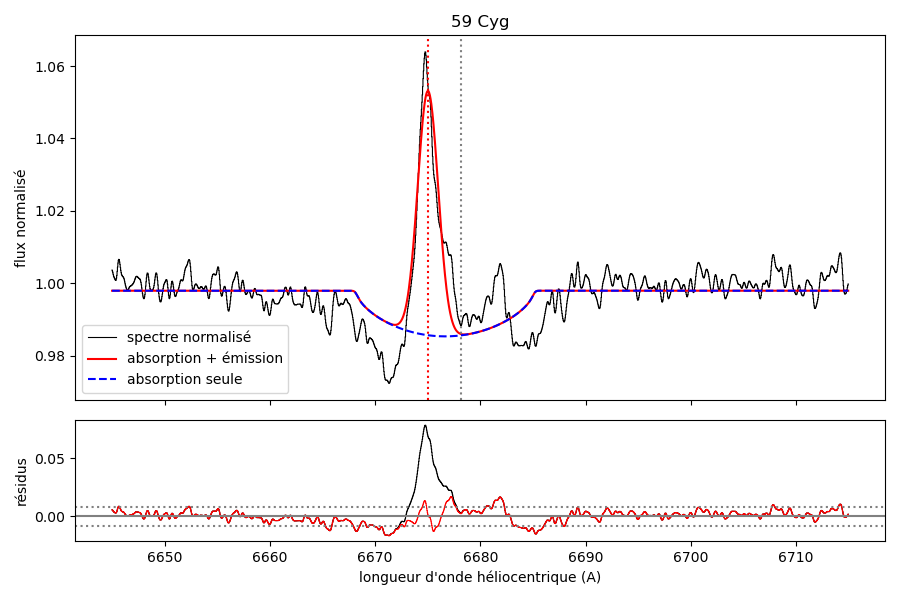

In [115]:
res = fit_hei(x_data, y_data, jd=float(sp.meta['header']['JD-OBS']), label='59 Cyg', vsini_fixed=379)
